In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('StudentsPerformance.csv')

print(df.head())
print(df.describe())
print(df.info())

   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
       math score  reading score  writing score
count  1000.00000    1000.000000    1000.000000
mean     66.08900      69.169000      68.054000
std      15.163

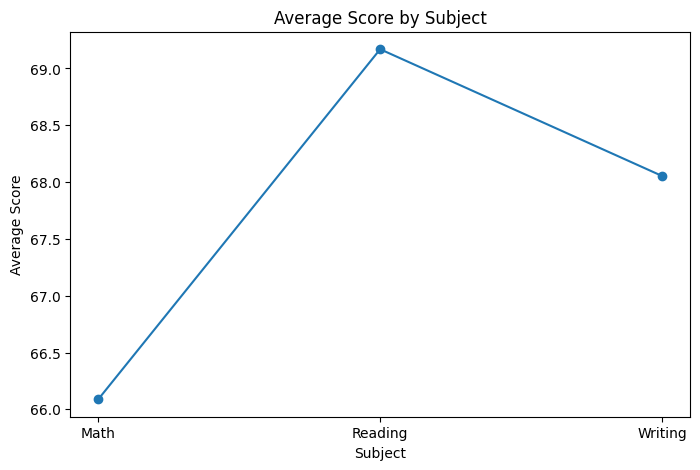

In [3]:
# 1. Line Plot - Average Scores
average_scores = [
    df['math score'].mean(),
    df['reading score'].mean(),
    df['writing score'].mean()
]

subjects = ['Math', 'Reading', 'Writing']

plt.figure(figsize=(8, 5))
plt.plot(subjects, average_scores, marker='o')
plt.title('Average Score by Subject')
plt.xlabel('Subject')
plt.ylabel('Average Score')
plt.show()


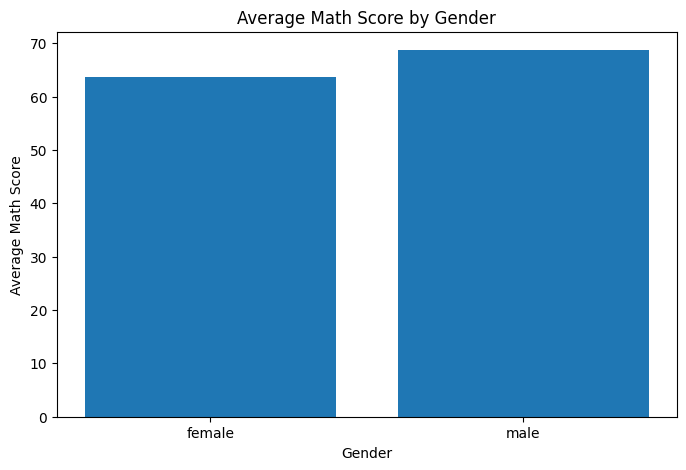

In [4]:


# 2. Bar Plot - Average Math Score by Gender
gender_avg = df.groupby('gender')['math score'].mean()

plt.figure(figsize=(8, 5))
plt.bar(gender_avg.index, gender_avg.values)
plt.title('Average Math Score by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Math Score')
plt.show()

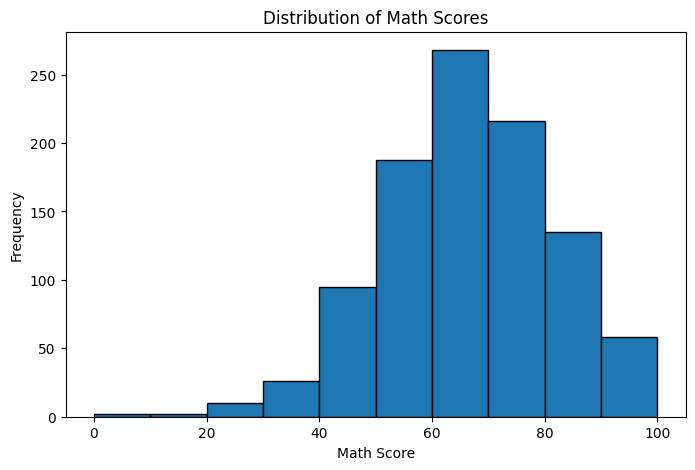

In [5]:
# 3. Histogram - Math Score Distribution
plt.figure(figsize=(8, 5))
plt.hist(df['math score'], bins=10, edgecolor='black')
plt.title('Distribution of Math Scores')
plt.xlabel('Math Score')
plt.ylabel('Frequency')
plt.show()


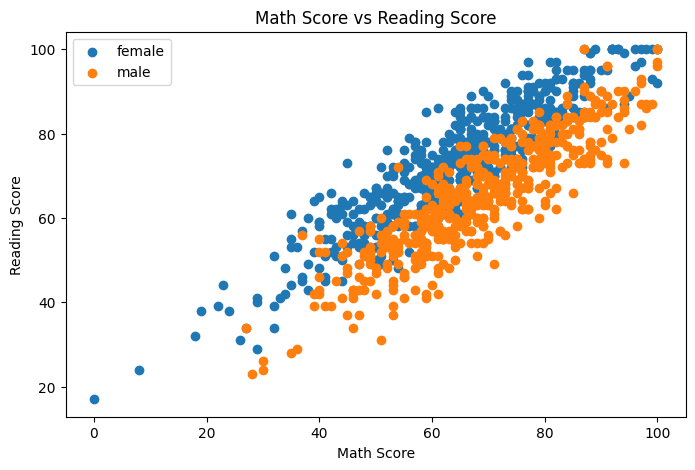

In [6]:

# 4. Scatter Plot - Math vs Reading Score
plt.figure(figsize=(8, 5))

for gender in df['gender'].unique():
    data = df[df['gender'] == gender]
    plt.scatter(
        data['math score'],
        data['reading score'],
        label=gender
    )

plt.title('Math Score vs Reading Score')
plt.xlabel('Math Score')
plt.ylabel('Reading Score')
plt.legend()
plt.show()

/var/folders/p2/mxw25sj55dl_7pjghjdc00hr0000gn/T/ipykernel_7110/3792046703.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


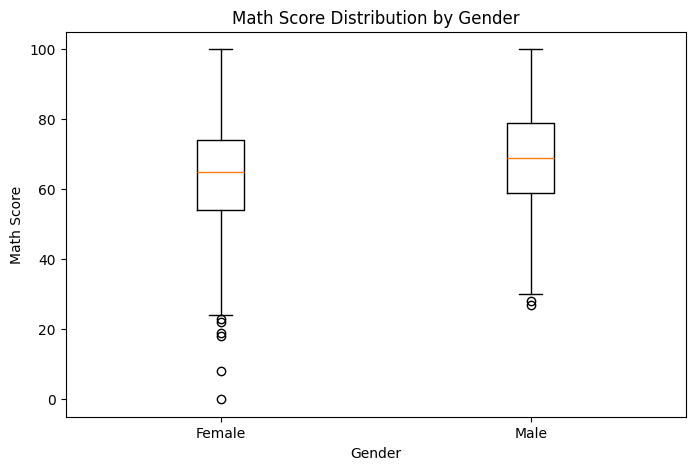

In [7]:
# 5. Box Plot - Math Scores by Gender
female_scores = df[df['gender'] == 'female']['math score']
male_scores = df[df['gender'] == 'male']['math score']

plt.figure(figsize=(8, 5))
plt.boxplot(
    [female_scores, male_scores],
    labels=['Female', 'Male']
)
plt.title('Math Score Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Math Score')
plt.show()


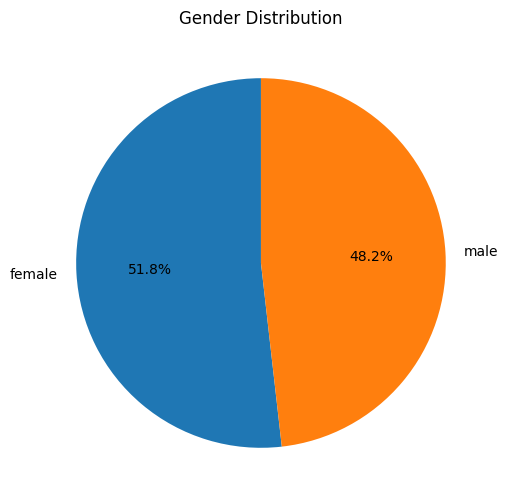

In [8]:

# 6. Pie Chart - Gender Distribution
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Gender Distribution')
plt.show()

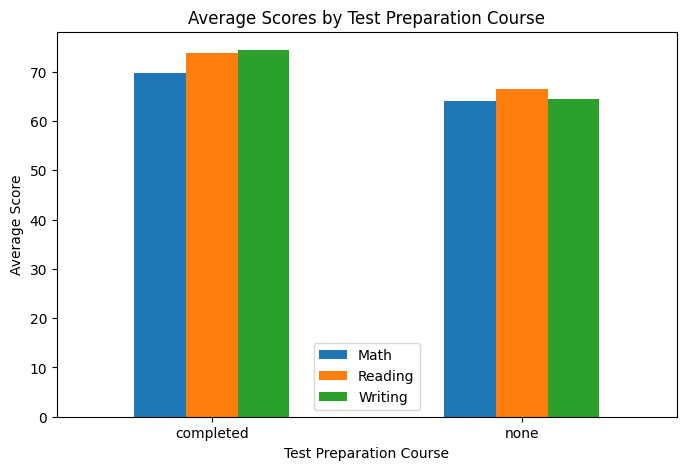

In [9]:

# 7. Bar Plot - Average Scores by Test Preparation
prep_avg = df.groupby('test preparation course')[
    ['math score', 'reading score', 'writing score']
].mean()

prep_avg.plot(kind='bar', figsize=(8, 5))

plt.title('Average Scores by Test Preparation Course')
plt.xlabel('Test Preparation Course')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.legend(['Math', 'Reading', 'Writing'])
plt.show()


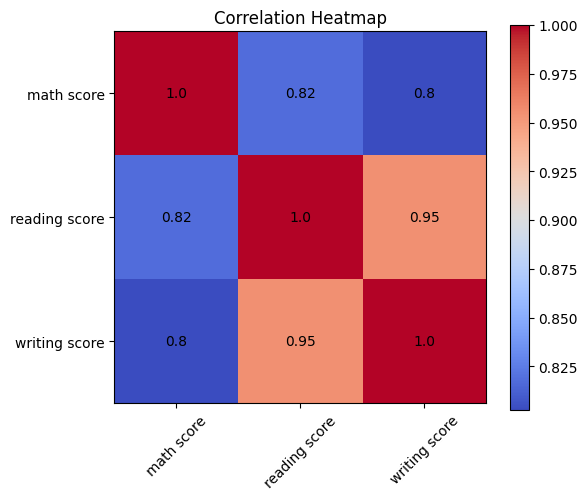

In [10]:

# 8. Heatmap - Correlation between Scores
correlation = df[
    ['math score', 'reading score', 'writing score']
].corr()

plt.figure(figsize=(6, 5))
plt.imshow(correlation, cmap='coolwarm')

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j,
            i,
            round(correlation.iloc[i, j], 2),
            ha='center',
            va='center'
        )

plt.title('Correlation Heatmap')
plt.show()